In [2]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from ml.features.time_features import (
    TimeFeatureConfig,
    build_time_features,
    get_model_columns,
)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

In [3]:
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

INPUT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "daily_revenue.csv"
)

OUTPUT_PATH = (
    PROJECT_ROOT
    / "data"
    / "features"
    / "sales_time_features.csv"
)

METADATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "features"
    / "sales_time_features_metadata.json"
)

OUTPUT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)

daily_sales = pd.read_csv(
    INPUT_PATH,
    parse_dates=["date"],
)

daily_sales.head()

,date,gross_revenue,transaction_lines,invoices,return_revenue,return_lines,net_revenue,return_rate,year,month,day_of_week,is_weekend
0,2009-12-01,54351.23,3068.0,119.0,-1340.47,110.0,53010.76,0.024663,2009,12,1,0
1,2009-12-02,63172.58,3208.0,115.0,-588.92,20.0,62583.66,0.009322,2009,12,2,0
2,2009-12-03,73972.45,2931.0,124.0,-5944.86,44.0,68027.59,0.080366,2009,12,3,0
3,2009-12-04,40582.32,2479.0,89.0,-386.52,27.0,40195.80,0.009524,2009,12,4,0
4,2009-12-05,9803.05,400.0,30.0,0.00,0.0,9803.05,0.000000,2009,12,5,1


In [4]:
# Validate
required_columns = {
    "date",
    "net_revenue",
}

missing_columns = (
    required_columns
    - set(daily_sales.columns)
)

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

assert daily_sales["date"].notna().all()
assert daily_sales["net_revenue"].notna().all()
assert daily_sales["date"].is_unique



In [5]:
daily_sales = (
    daily_sales[
        [
            "date",
            "net_revenue",
        ]
    ]
    .sort_values("date")
    .reset_index(drop=True)
)

daily_sales.info()
daily_sales.head()
daily_sales.tail()

<class 'pandas.DataFrame'>
RangeIndex: 739 entries, 0 to 738
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         739 non-null    datetime64[us]
 1   net_revenue  739 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 11.7 KB


,date,net_revenue
734,2011-12-05,57630.20
735,2011-12-06,54109.39
736,2011-12-07,74952.61
737,2011-12-08,81294.33
738,2011-12-09,32129.91


In [6]:
# check missing dates
full_date_range = pd.date_range(
    start=daily_sales["date"].min(),
    end=daily_sales["date"].max(),
    freq="D",
)

missing_dates = full_date_range.difference(
    daily_sales["date"]
)

print("Missing dates:", len(missing_dates))
print(missing_dates[:10])

Missing dates: 0
DatetimeIndex([], dtype='datetime64[us]', freq='D')


In [7]:
daily_sales = (
    daily_sales
    .set_index("date")
    .reindex(full_date_range)
    .rename_axis("date")
    .reset_index()
)

daily_sales["net_revenue"] = (
    daily_sales["net_revenue"]
    .fillna(0)
)

In [8]:
# init configuration
config = TimeFeatureConfig(
    date_column="date",
    target_column="net_revenue",
    lags=(
        1,
        7,
        14,
        28,
        30,
        60,
        90,
    ),
    rolling_windows=(
        7,
        14,
        30,
    ),
    expanding_min_periods=7,
    add_cyclical_features=True,
)
features_all = build_time_features(
    daily_sales,
    config=config,
    drop_incomplete_rows=False,
)

print(features_all.shape)
features_all.head(10)

(739, 45)


,date,net_revenue,day_of_week,day_of_month,day_of_year,week_of_year,month,quarter,year,is_weekend,is_month_start,is_month_end,is_quarter_start,is_quarter_end,day_of_week_sin,day_of_week_cos,month_sin,month_cos,quarter_sin,quarter_cos,day_of_year_sin,day_of_year_cos,net_revenue_lag_1,net_revenue_lag_7,net_revenue_lag_14,net_revenue_lag_28,net_revenue_lag_30,net_revenue_lag_60,net_revenue_lag_90,net_revenue_rolling_mean_7,net_revenue_rolling_std_7,net_revenue_rolling_min_7,net_revenue_rolling_max_7,net_revenue_rolling_mean_14,net_revenue_rolling_std_14,net_revenue_rolling_min_14,net_revenue_rolling_max_14,net_revenue_rolling_mean_30,net_revenue_rolling_std_30,net_revenue_rolling_min_30,net_revenue_rolling_max_30,net_revenue_expanding_mean,net_revenue_expanding_std,net_revenue_expanding_min,net_revenue_expanding_max
0,2009-12-01,53010.76,1,1,335,49,12,4,2009,0,1,0,0,0,0.781831,0.623490,-2.449294e-16,1.0,-2.449294e-16,1.0,-0.497204,0.867634,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2009-12-02,62583.66,2,2,336,49,12,4,2009,0,0,0,0,0,0.974928,-0.222521,-2.449294e-16,1.0,-2.449294e-16,1.0,-0.482206,0.876058,53010.76,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2009-12-03,68027.59,3,3,337,49,12,4,2009,0,0,0,0,0,0.433884,-0.900969,-2.449294e-16,1.0,-2.449294e-16,1.0,-0.467065,0.884223,62583.66,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2009-12-04,40195.80,4,4,338,49,12,4,2009,0,0,0,0,0,-0.433884,-0.900969,-2.449294e-16,1.0,-2.449294e-16,1.0,-0.451786,0.892126,68027.59,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2009-12-05,9803.05,5,5,339,49,12,4,2009,1,0,0,0,0,-0.974928,-0.222521,-2.449294e-16,1.0,-2.449294e-16,1.0,-0.436373,0.899766,40195.80,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2009-12-06,24126.58,6,6,340,49,12,4,2009,1,0,0,0,0,-0.781831,0.623490,-2.449294e-16,1.0,-2.449294e-16,1.0,-0.420831,0.907139,9803.05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2009-12-07,44169.88,0,7,341,50,12,4,2009,0,0,0,0,0,0.000000,1.000000,-2.449294e-16,1.0,-2.449294e-16,1.0,-0.405165,0.914244,24126.58,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2009-12-08,43702.14,1,8,342,50,12,4,2009,0,0,0,0,0,0.781831,0.623490,-2.449294e-16,1.0,-2.449294e-16,1.0,-0.389378,0.921078,44169.88,53010.76,NaN,NaN,NaN,NaN,NaN,43131.045714,19188.801547,9803.05,68027.59,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43131.045714,19188.801547,9803.05,68027.59
8,2009-12-09,40046.12,2,9,343,50,12,4,2009,0,0,0,0,0,0.974928,-0.222521,-2.449294e-16,1.0,-2.449294e-16,1.0,-0.373477,0.927640,43702.14,62583.66,NaN,NaN,NaN,NaN,NaN,41801.242857,18776.160792,9803.05,68027.59,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43202.432500,17950.473928,9803.05,68027.59
9,2009-12-10,43134.33,3,10,344,50,12,4,2009,0,0,0,0,0,0.433884,-0.900969,-2.449294e-16,1.0,-2.449294e-16,1.0,-0.357464,0.933927,40046.12,68027.59,NaN,NaN,NaN,NaN,NaN,38581.594286,16760.575059,9803.05,68027.59,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42851.731111,16952.913546,9803.05,68027.59


In [9]:
# check
missing_summary = (
    features_all
    .isna()
    .sum()
    .sort_values(ascending=False)
)

missing_summary[
    missing_summary > 0
]


net_revenue_lag_90             90
net_revenue_lag_60             60
net_revenue_lag_30             30
net_revenue_rolling_max_30     30
net_revenue_rolling_mean_30    30
net_revenue_rolling_std_30     30
net_revenue_rolling_min_30     30
net_revenue_lag_28             28
net_revenue_lag_14             14
net_revenue_rolling_max_14     14
net_revenue_rolling_min_14     14
net_revenue_rolling_std_14     14
net_revenue_rolling_mean_14    14
net_revenue_expanding_mean      7
net_revenue_expanding_std       7
net_revenue_rolling_min_7       7
net_revenue_rolling_max_7       7
net_revenue_expanding_min       7
net_revenue_expanding_max       7
net_revenue_rolling_std_7       7
net_revenue_rolling_mean_7      7
net_revenue_lag_7               7
net_revenue_lag_1               1
dtype: int64

In [10]:
# target leakage
expected_lag_1 = (
    features_all["net_revenue"]
    .shift(1)
)

pd.testing.assert_series_equal(
    features_all["net_revenue_lag_1"],
    expected_lag_1,
    check_names=False,
)

print("lag_1 check passed")

lag_1 check passed


In [11]:
# check rolling mean 7
expected_rolling_mean_7 = (
    features_all["net_revenue"]
    .shift(1)
    .rolling(7)
    .mean()
)

pd.testing.assert_series_equal(
    features_all[
        "net_revenue_rolling_mean_7"
    ],
    expected_rolling_mean_7,
    check_names=False,
)

print("rolling_mean_7 leakage check passed")

rolling_mean_7 leakage check passed


In [12]:
feature_dataset = build_time_features(
    daily_sales,
    config=config,
    drop_incomplete_rows=True,
)

print(
    "Original rows:",
    len(daily_sales),
)

print(
    "Model-ready rows:",
    len(feature_dataset),
)

print(
    "Removed rows:",
    len(daily_sales) - len(feature_dataset),
)


Original rows: 739
Model-ready rows: 649
Removed rows: 90


In [13]:
# Check
assert not feature_dataset.isna().any().any()
assert feature_dataset["date"].is_monotonic_increasing

feature_dataset.head()

,date,net_revenue,day_of_week,day_of_month,day_of_year,week_of_year,month,quarter,year,is_weekend,is_month_start,is_month_end,is_quarter_start,is_quarter_end,day_of_week_sin,day_of_week_cos,month_sin,month_cos,quarter_sin,quarter_cos,day_of_year_sin,day_of_year_cos,net_revenue_lag_1,net_revenue_lag_7,net_revenue_lag_14,net_revenue_lag_28,net_revenue_lag_30,net_revenue_lag_60,net_revenue_lag_90,net_revenue_rolling_mean_7,net_revenue_rolling_std_7,net_revenue_rolling_min_7,net_revenue_rolling_max_7,net_revenue_rolling_mean_14,net_revenue_rolling_std_14,net_revenue_rolling_min_14,net_revenue_rolling_max_14,net_revenue_rolling_mean_30,net_revenue_rolling_std_30,net_revenue_rolling_min_30,net_revenue_rolling_max_30,net_revenue_expanding_mean,net_revenue_expanding_std,net_revenue_expanding_min,net_revenue_expanding_max
0,2010-03-01,25339.94,0,1,60,9,3,1,2010,0,1,0,0,0,0.000000,1.000000,1.0,6.123234e-17,1.0,6.123234e-17,0.858402,0.512978,16630.44,26213.600,40775.981,18470.951,0.000,0.00,53010.76,22396.453143,13465.408170,0.0,45379.53,22967.393857,13389.953563,0.0,45379.53,18295.467533,11566.922471,0.0,45379.53,21662.735867,17910.451212,0.0,72744.97
1,2010-03-02,25637.71,1,2,61,9,3,1,2010,0,0,0,0,0,0.781831,0.623490,1.0,6.123234e-17,1.0,6.123234e-17,0.867099,0.498137,25339.94,22505.110,30893.880,20819.310,18345.800,0.00,62583.66,22271.644571,13433.460275,0.0,45379.53,21864.819500,12482.947815,0.0,45379.53,19140.132200,11116.515599,0.0,45379.53,21703.144703,17815.895136,0.0,72744.97
2,2010-03-03,33833.59,2,3,62,9,3,1,2010,0,0,0,0,0,0.974928,-0.222521,1.0,6.123234e-17,1.0,6.123234e-17,0.875539,0.483147,25637.71,32790.091,22598.950,21272.761,18470.951,0.00,68027.59,22719.158857,13485.860277,0.0,45379.53,21489.378786,12283.185938,0.0,45379.53,19383.195867,11176.049879,0.0,45379.53,21745.911717,17723.501166,0.0,72744.97
3,2010-03-04,31540.73,3,4,63,9,3,1,2010,0,0,0,0,0,0.433884,-0.900969,1.0,6.123234e-17,1.0,6.123234e-17,0.883720,0.468015,33833.59,45379.530,34168.310,22484.090,20819.310,0.00,40195.80,22868.230143,13601.629847,0.0,45379.53,22291.853071,12689.720496,0.0,45379.53,19895.283833,11470.596329,0.0,45379.53,21875.886753,17671.984475,0.0,72744.97
4,2010-03-05,27536.73,4,5,64,9,3,1,2010,0,0,0,0,0,-0.433884,-0.900969,1.0,6.123234e-17,1.0,6.123234e-17,0.891640,0.452745,31540.73,13256.401,27092.620,20714.720,21272.761,13165.15,9803.05,20891.258714,10929.155384,0.0,33833.59,22104.168786,12531.116777,0.0,45379.53,20252.664500,11659.285810,0.0,45379.53,21978.704234,17605.676599,0.0,72744.97


In [14]:
# feature columns
feature_columns, target_column = (
    get_model_columns(
        feature_dataset,
        date_column="date",
        target_column="net_revenue",
    )
)

print("Target:")
print(target_column)

print("\nNumber of features:")
print(len(feature_columns))

print("\nFeatures:")
for feature in feature_columns:
    print(feature)

Target:
net_revenue

Number of features:
43

Features:
day_of_week
day_of_month
day_of_year
week_of_year
month
quarter
year
is_weekend
is_month_start
is_month_end
is_quarter_start
is_quarter_end
day_of_week_sin
day_of_week_cos
month_sin
month_cos
quarter_sin
quarter_cos
day_of_year_sin
day_of_year_cos
net_revenue_lag_1
net_revenue_lag_7
net_revenue_lag_14
net_revenue_lag_28
net_revenue_lag_30
net_revenue_lag_60
net_revenue_lag_90
net_revenue_rolling_mean_7
net_revenue_rolling_std_7
net_revenue_rolling_min_7
net_revenue_rolling_max_7
net_revenue_rolling_mean_14
net_revenue_rolling_std_14
net_revenue_rolling_min_14
net_revenue_rolling_max_14
net_revenue_rolling_mean_30
net_revenue_rolling_std_30
net_revenue_rolling_min_30
net_revenue_rolling_max_30
net_revenue_expanding_mean
net_revenue_expanding_std
net_revenue_expanding_min
net_revenue_expanding_max


In [15]:
X = feature_dataset[feature_columns]
y = feature_dataset[target_column]
dates = feature_dataset["date"]

print("X shape:", X.shape)
print("y shape:", y.shape)

assert len(X) == len(y)
assert not X.isna().any().any()
assert not y.isna().any()

X shape: (649, 43)
y shape: (649,)


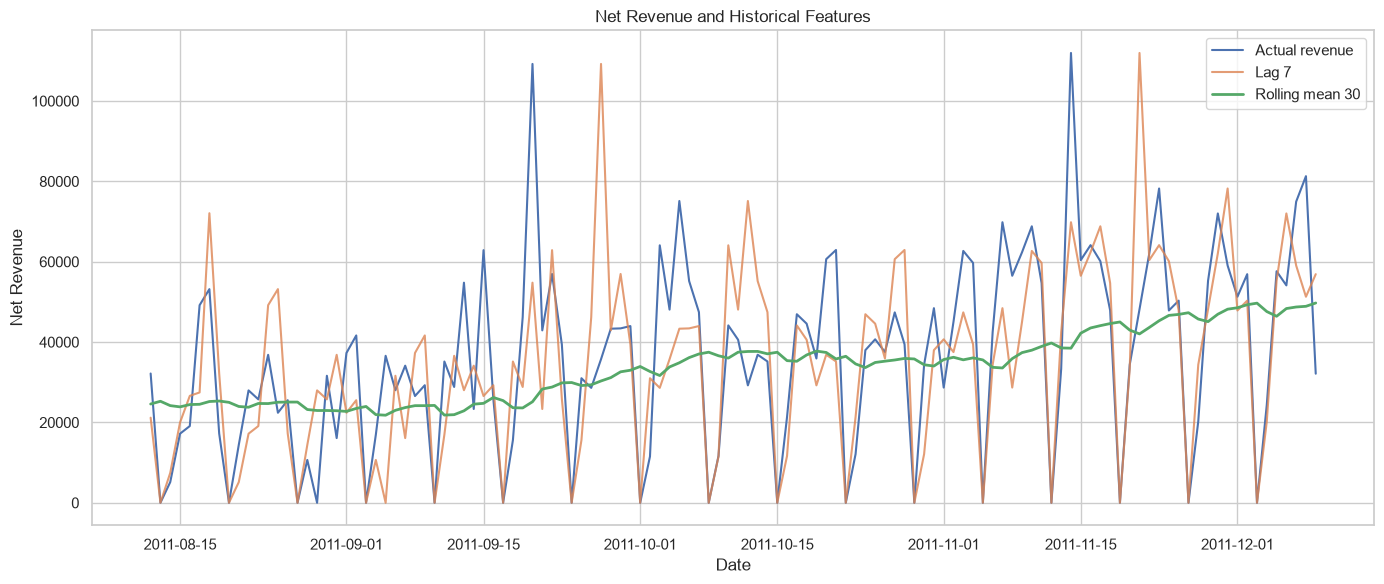

In [17]:
# Revenue and lag
plot_data = feature_dataset.tail(120)

plt.figure(figsize=(14, 6))

plt.plot(
    plot_data["date"],
    plot_data["net_revenue"],
    label="Actual revenue",
)

plt.plot(
    plot_data["date"],
    plot_data["net_revenue_lag_7"],
    label="Lag 7",
    alpha=0.8,
)

plt.plot(
    plot_data["date"],
    plot_data["net_revenue_rolling_mean_30"],
    label="Rolling mean 30",
    linewidth=2,
)

plt.title(
    "Net Revenue and Historical Features"
)

plt.xlabel("Date")
plt.ylabel("Net Revenue")
plt.legend()
plt.tight_layout()
plt.show()

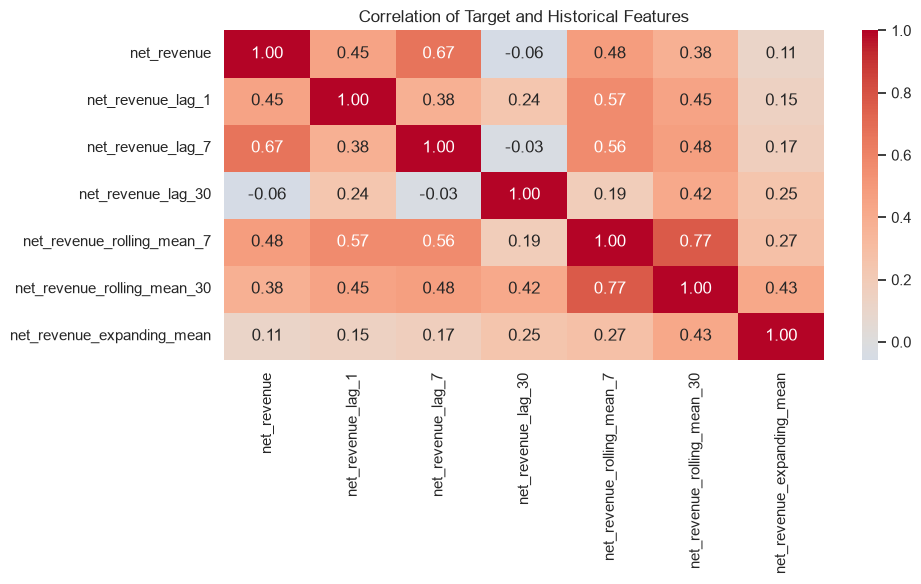

In [18]:
# Correlation heatmap
selected_columns = [
    "net_revenue",
    "net_revenue_lag_1",
    "net_revenue_lag_7",
    "net_revenue_lag_30",
    "net_revenue_rolling_mean_7",
    "net_revenue_rolling_mean_30",
    "net_revenue_expanding_mean",
]

correlation = (
    feature_dataset[selected_columns]
    .corr()
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    center=0,
    cmap="coolwarm",
)

plt.title(
    "Correlation of Target and Historical Features"
)

plt.tight_layout()
plt.show()

In [19]:
feature_dataset.to_csv(
    OUTPUT_PATH,
    index=False,
)

print(
    f"Saved feature dataset: {OUTPUT_PATH}"
)

Saved feature dataset: D:\Research_Project\sales-forecasting-platform\data\features\sales_time_features.csv


In [20]:
# save feature metadata
metadata = {
    "date_column": config.date_column,
    "target_column": target_column,
    "feature_columns": feature_columns,
    "lags": list(config.lags),
    "rolling_windows": list(
        config.rolling_windows
    ),
    "expanding_min_periods": (
        config.expanding_min_periods
    ),
    "row_count": len(feature_dataset),
    "start_date": str(
        feature_dataset["date"]
        .min()
        .date()
    ),
    "end_date": str(
        feature_dataset["date"]
        .max()
        .date()
    ),
}

METADATA_PATH.write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    f"Saved metadata: {METADATA_PATH}"
)

Saved metadata: D:\Research_Project\sales-forecasting-platform\data\features\sales_time_features_metadata.json


In [21]:
saved_metadata = json.loads(
    METADATA_PATH.read_text(
        encoding="utf-8"
    )
)

saved_metadata

{'date_column': 'date',
 'target_column': 'net_revenue',
 'feature_columns': ['day_of_week',
  'day_of_month',
  'day_of_year',
  'week_of_year',
  'month',
  'quarter',
  'year',
  'is_weekend',
  'is_month_start',
  'is_month_end',
  'is_quarter_start',
  'is_quarter_end',
  'day_of_week_sin',
  'day_of_week_cos',
  'month_sin',
  'month_cos',
  'quarter_sin',
  'quarter_cos',
  'day_of_year_sin',
  'day_of_year_cos',
  'net_revenue_lag_1',
  'net_revenue_lag_7',
  'net_revenue_lag_14',
  'net_revenue_lag_28',
  'net_revenue_lag_30',
  'net_revenue_lag_60',
  'net_revenue_lag_90',
  'net_revenue_rolling_mean_7',
  'net_revenue_rolling_std_7',
  'net_revenue_rolling_min_7',
  'net_revenue_rolling_max_7',
  'net_revenue_rolling_mean_14',
  'net_revenue_rolling_std_14',
  'net_revenue_rolling_min_14',
  'net_revenue_rolling_max_14',
  'net_revenue_rolling_mean_30',
  'net_revenue_rolling_std_30',
  'net_revenue_rolling_min_30',
  'net_revenue_rolling_max_30',
  'net_revenue_expanding_me

In [22]:
print("Dataset shape:", feature_dataset.shape)

print(
    "Date range:",
    feature_dataset["date"].min(),
    "->",
    feature_dataset["date"].max(),
)

print(
    "Target:",
    target_column,
)

print(
    "Number of features:",
    len(feature_columns),
)

print(
    "Missing values:",
    feature_dataset.isna().sum().sum(),
)

print(
    "Duplicate dates:",
    feature_dataset["date"].duplicated().sum(),
)

assert feature_dataset["date"].is_unique
assert feature_dataset["date"].is_monotonic_increasing
assert feature_dataset.isna().sum().sum() == 0



Dataset shape: (649, 45)
Date range: 2010-03-01 00:00:00 -> 2011-12-09 00:00:00
Target: net_revenue
Number of features: 43
Missing values: 0
Duplicate dates: 0
